In [1]:
from pathlib import Path
import shutil

source = Path(r"C:\Users\ragin\final_validated_dataset.csv")

destination = Path(
    r"C:\Users\ragin\axlero-data-analytics\data\processed\final_validated_dataset.csv"
)

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.copy2(source, destination)

print("File copied successfully:", destination.exists())
print("File location:", destination)

File copied successfully: True
File location: C:\Users\ragin\axlero-data-analytics\data\processed\final_validated_dataset.csv


In [2]:
import pandas as pd

df = pd.read_csv(destination)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (32416, 12)

Column Names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,4.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21.0,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
output_dir = Path(
    r"C:\Users\ragin\axlero-data-analytics\reports\member3_outputs"
)

output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder ready:", output_dir.exists())

Output folder ready: True


In [4]:
# Define the target variable
target = "loan_status"

# Identify numerical features
numerical_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

# Check whether all features exist
missing_features = [
    col for col in numerical_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(f"Missing features: {missing_features}")

# Display numerical features
print("Numerical Features:")
for feature in numerical_features:
    print(feature)

print("\nTotal Numerical Features:", len(numerical_features))

# Descriptive statistics
display(df[numerical_features].describe())

Numerical Features:
person_age
person_income
person_emp_length
loan_amnt
loan_int_rate
loan_percent_income
cb_person_cred_hist_length

Total Numerical Features: 7


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000
mean,27.730102,6.609164e+04,4.761538,9593.845632,11.020159,0.170250,5.811297
std,6.210006,6.201558e+04,3.983588,6322.730241,3.213380,0.106812,4.059030
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.000000,5000.000000,7.880000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.000000,12250.000000,13.480000,0.230000,8.000000
max,94.000000,6.000000e+06,41.000000,35000.000000,23.220000,0.830000,30.000000


In [5]:

# Pearson correlation between numerical features

pearson_corr = df[numerical_features].corr(method="pearson")

print("Pearson Correlation Matrix:")
display(pearson_corr.round(3))


Pearson Correlation Matrix:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
person_age,1.000,0.118,0.171,0.051,0.011,-0.042,0.878
person_income,0.118,1.000,0.137,0.266,-0.003,-0.254,0.118
person_emp_length,0.171,0.137,1.000,0.112,-0.053,-0.058,0.148
loan_amnt,0.051,0.266,0.112,1.000,0.142,0.573,0.042
loan_int_rate,0.011,-0.003,-0.053,0.142,1.000,0.121,0.015
loan_percent_income,-0.042,-0.254,-0.058,0.573,0.121,1.000,-0.031
cb_person_cred_hist_length,0.878,0.118,0.148,0.042,0.015,-0.031,1.000


In [6]:

# Calculate Spearman correlation
spearman_corr = df[numerical_features].corr(method="spearman")

print("Spearman Correlation Matrix:")
display(spearman_corr.round(3))


Spearman Correlation Matrix:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
person_age,1.000,0.144,0.102,0.064,0.009,-0.058,0.806
person_income,0.144,1.000,0.209,0.406,-0.038,-0.367,0.092
person_emp_length,0.102,0.209,1.000,0.108,-0.063,-0.057,0.067
loan_amnt,0.064,0.406,0.108,1.000,0.103,0.654,0.042
loan_int_rate,0.009,-0.038,-0.063,0.103,1.000,0.125,0.012
loan_percent_income,-0.058,-0.367,-0.057,0.654,0.125,1.000,-0.037
cb_person_cred_hist_length,0.806,0.092,0.067,0.042,0.012,-0.037,1.000


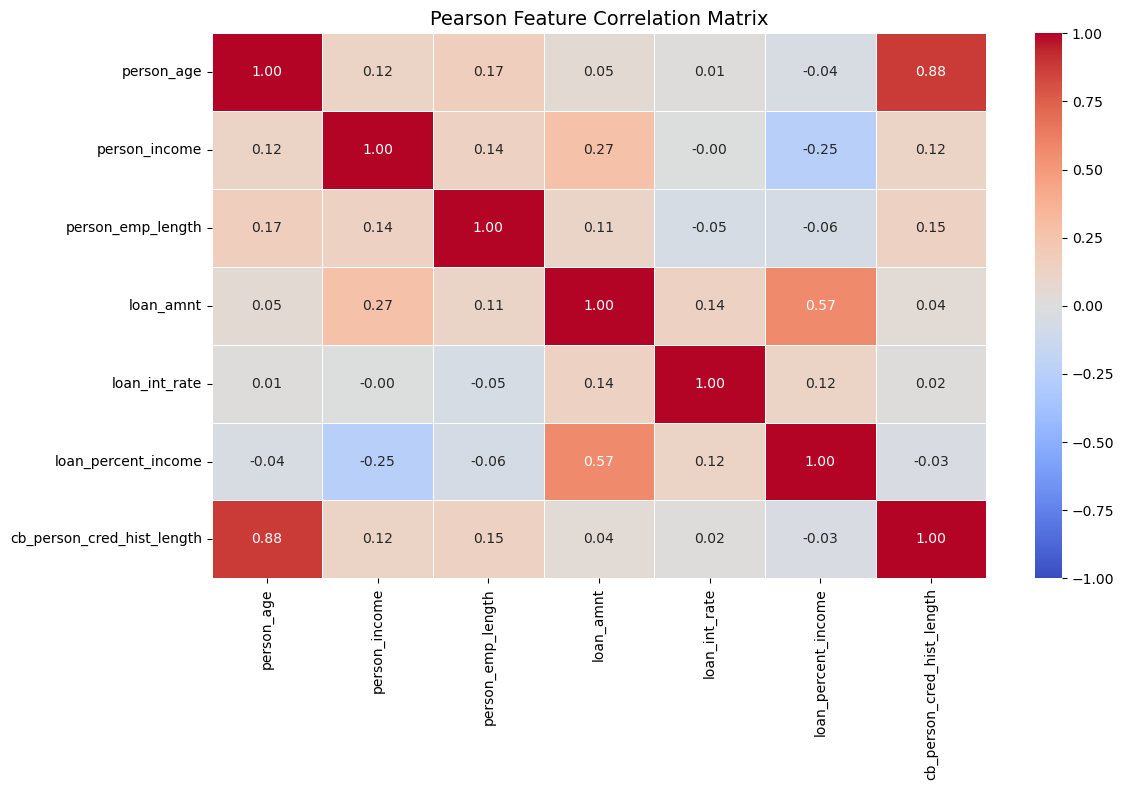

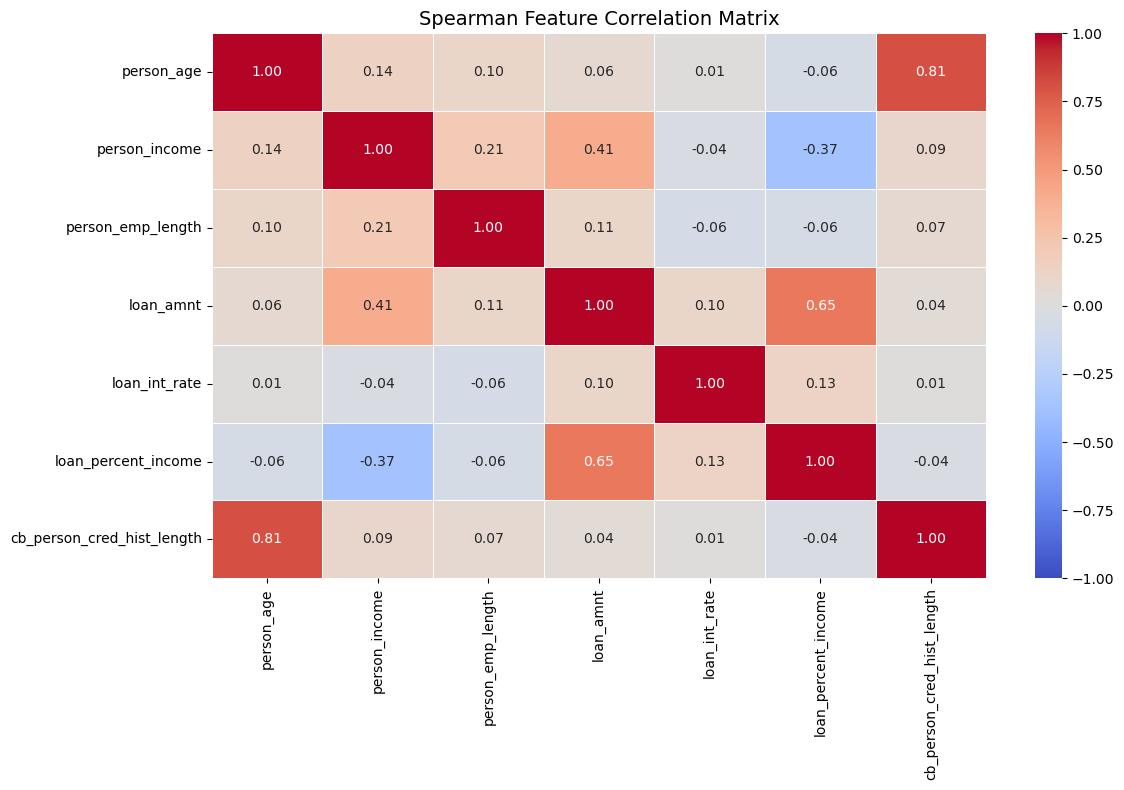

Both correlation heatmaps saved successfully.


In [7]:

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Define output folder
output_dir = Path(
    r"C:\Users\ragin\axlero-data-analytics\reports\member3_outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Create Pearson heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Pearson Feature Correlation Matrix", fontsize=14)
plt.tight_layout()

plt.savefig(
    output_dir / "pearson_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Create Spearman heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Spearman Feature Correlation Matrix", fontsize=14)
plt.tight_layout()

plt.savefig(
    output_dir / "spearman_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both correlation heatmaps saved successfully.")


In [8]:

# Identify highly correlated feature pairs

import numpy as np
import pandas as pd

threshold = 0.80

# Select only the upper triangle to avoid duplicate pairs
upper_triangle = pearson_corr.where(
    np.triu(
        np.ones(pearson_corr.shape),
        k=1
    ).astype(bool)
)

# Convert correlation matrix to a table
correlation_pairs = upper_triangle.stack().reset_index()

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Pearson_Correlation"
]

# Calculate absolute correlation
correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Pearson_Correlation"].abs()
)

# Sort by strongest relationship
correlation_pairs = correlation_pairs.sort_values(
    "Absolute_Correlation",
    ascending=False
)

# Filter highly correlated feature pairs
high_corr_pairs = correlation_pairs[
    correlation_pairs["Absolute_Correlation"] >= threshold
].copy()

print("Highly Correlated Feature Pairs:")
display(high_corr_pairs)

print("Total Highly Correlated Pairs:", len(high_corr_pairs))


Highly Correlated Feature Pairs:


,Feature_1,Feature_2,Pearson_Correlation,Absolute_Correlation
5,person_age,cb_person_cred_hist_length,0.877886,0.877886


Total Highly Correlated Pairs: 1


In [9]:

# Save professional analysis outputs

pearson_corr.to_csv(
    output_dir / "pearson_correlation_matrix.csv"
)

spearman_corr.to_csv(
    output_dir / "spearman_correlation_matrix.csv"
)

correlation_pairs.to_csv(
    output_dir / "feature_correlation_pairs.csv",
    index=False
)

high_corr_pairs.to_csv(
    output_dir / "high_correlation_pairs.csv",
    index=False
)

print("Correlation results saved successfully.")

print("\nSaved files:")
for file in output_dir.glob("*correlation*"):
    print(file.name)


Correlation results saved successfully.

Saved files:
feature_correlation_pairs.csv
high_correlation_pairs.csv
pearson_correlation_heatmap.png
pearson_correlation_matrix.csv
spearman_correlation_heatmap.png
spearman_correlation_matrix.csv


In [10]:
import os
print(os.getcwd())

C:\Users\ragin


# Multicollinearity and Statistical Significance Validation

In [3]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import train_test_split

# Define project location
project_dir = Path(r"C:\Users\ragin\axlero-data-analytics")

# Dataset path
data_path = project_dir / "data" / "processed" / "final_validated_dataset.csv"

# Load dataset
df = pd.read_csv(data_path)

# Numerical features
numerical_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

target = "loan_status"

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (32416, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,4.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21.0,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df[target]
)

X_train = train_df[numerical_features].copy()

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nMissing values:")
display(X_train.isnull().sum())

Training dataset shape: (25932, 12)
Testing dataset shape: (6484, 12)

Missing values:


person_age                    0
person_income                 0
person_emp_length             0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_cred_hist_length    0
dtype: int64

In [5]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select the training predictors
X_vif = X_train.astype(float).copy()

# Add intercept
X_vif_constant = add_constant(X_vif, has_constant="add")

# Calculate VIF for each numerical feature
vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_constant.values, i + 1
        )
        for i in range(len(X_vif.columns))
    ]
})

# Sort features by VIF
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

print("Variance Inflation Factor (VIF) Results:")
display(vif_results.round(3))


Variance Inflation Factor (VIF) Results:


,Feature,VIF
0,person_age,4.378
1,cb_person_cred_hist_length,4.349
2,loan_amnt,2.058
3,loan_percent_income,2.019
4,person_income,1.444
5,person_emp_length,1.065
6,loan_int_rate,1.026



## Multicollinearity Analysis — VIF Findings

### Objective
Evaluate multicollinearity among numerical predictors
using Variance Inflation Factor (VIF).

### Methodology
- Used the training dataset containing 25,932 records.
- Evaluated seven numerical predictors.
- Included an intercept in the VIF calculation.
- Used VIF > 5 as an investigation threshold.

### Results
- person_age: 4.378
- cb_person_cred_hist_length: 4.349
- loan_amnt: 2.058
- loan_percent_income: 2.019
- person_income: 1.444
- person_emp_length: 1.065
- loan_int_rate: 1.026

### Findings
All seven numerical predictors have VIF values below 5.

Person age and credit history length have the highest
VIF values, consistent with their strong correlation.

### Conclusion
No numerical features are removed based solely on VIF.

Final feature selection will consider predictive
importance, statistical significance, redundancy,
and business relevance.


In [6]:
from pathlib import Path

output_dir = Path(
    r"C:\Users\ragin\axlero-data-analytics\reports\member3_outputs"
)

file_path = output_dir / "vif_results.csv"

print("File exists:", file_path.exists())
print("File location:", file_path)

File exists: False
File location: C:\Users\ragin\axlero-data-analytics\reports\member3_outputs\vif_results.csv


In [7]:
output_dir.mkdir(parents=True, exist_ok=True)

vif_results.to_csv(
    output_dir / "vif_results.csv",
    index=False
)

print("VIF results saved successfully!")

VIF results saved successfully!


In [8]:
import pandas as pd

saved_vif = pd.read_csv(file_path)

display(saved_vif)

,Feature,VIF
0,person_age,4.377520
1,cb_person_cred_hist_length,4.349290
2,loan_amnt,2.058443
3,loan_percent_income,2.019155
4,person_income,1.444325
5,person_emp_length,1.064508
6,loan_int_rate,1.026456


In [9]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

results = []

for feature in numerical_features:
    group_0 = train_df.loc[train_df[target] == 0, feature].dropna()
    group_1 = train_df.loc[train_df[target] == 1, feature].dropna()

    t_stat, p_value = ttest_ind(
        group_0, group_1, equal_var=False
    )

    results.append({
        "Feature": feature,
        "Non_Default_Mean": group_0.mean(),
        "Default_Mean": group_1.mean(),
        "T_Statistic": t_stat,
        "P_Value": p_value
    })

ttest_results = pd.DataFrame(results)

ttest_results["Adjusted_P_Value"] = multipletests(
    ttest_results["P_Value"],
    method="fdr_bh"
)[1]

ttest_results["Significant"] = (
    ttest_results["Adjusted_P_Value"] < 0.05
)

display(ttest_results.round(5))

,Feature,Non_Default_Mean,Default_Mean,T_Statistic,P_Value,Adjusted_P_Value,Significant
0,person_age,27.76620,27.48669,2.96700,0.00302,0.00352,True
1,person_income,70526.56216,49043.60712,31.62602,0.00000,0.00000,True
2,person_emp_length,4.91901,4.09434,14.39351,0.00000,0.00000,True
3,loan_amnt,9232.15167,10878.41651,-15.93318,0.00000,0.00000,True
4,loan_int_rate,10.45842,13.03765,-53.67803,0.00000,0.00000,True
5,loan_percent_income,0.14931,0.24738,-52.81496,0.00000,0.00000,True
6,cb_person_cred_hist_length,5.82957,5.68595,2.33309,0.01967,0.01967,True


In [10]:
ttest_results.to_csv(
    output_dir / "numerical_significance_results.csv",
    index=False
)

print("Numerical significance results saved successfully.")
print("File exists:", (output_dir / "numerical_significance_results.csv").exists())

Numerical significance results saved successfully.
File exists: True


In [11]:
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

chi_results = []

for feature in categorical_features:

    contingency_table = pd.crosstab(
        train_df[feature].fillna("Missing"),
        train_df[target]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_results.append({
        "Feature": feature,
        "Chi_Square": chi2,
        "Degrees_of_Freedom": dof,
        "P_Value": p_value,
        "Minimum_Expected_Frequency": expected.min()
    })

chi_square_results = pd.DataFrame(chi_results)

chi_square_results["Adjusted_P_Value"] = multipletests(
    chi_square_results["P_Value"],
    method="fdr_bh"
)[1]

chi_square_results["Significant"] = (
    chi_square_results["Adjusted_P_Value"] < 0.05
)

print("Categorical Feature Significance Results:")
display(chi_square_results.round(6))

Categorical Feature Significance Results:


,Feature,Chi_Square,Degrees_of_Freedom,P_Value,Minimum_Expected_Frequency,Adjusted_P_Value,Significant
0,person_home_ownership,1539.214732,3,0.0,19.244486,0.0,True
1,loan_intent,401.686874,5,0.0,616.916975,0.0,True
2,loan_grade,4438.308027,6,0.0,10.496992,0.0,True
3,cb_person_default_on_file,837.570123,1,0.0,1001.806687,0.0,True


In [12]:
chi_square_results.to_csv(
    output_dir / "categorical_significance_results.csv",
    index=False
)

print("File saved successfully!")
print(
    "File exists:",
    (output_dir / "categorical_significance_results.csv").exists()
)

File saved successfully!
File exists: True


## Multivariable Logistic Regression — Statistical Validation

In [13]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# Use training data only
model_features = numerical_features + categorical_features

X = train_df[model_features].copy()
y = train_df[target].astype(int)

# Standardize numerical variables
scaler = StandardScaler()
X[numerical_features] = scaler.fit_transform(
    X[numerical_features]
)

# One-hot encode categories, dropping one reference level
X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=float
)

# Ensure numerical design matrix
X = sm.add_constant(X.astype(float), has_constant="add")

# Fit multivariable logistic regression
logit_model = sm.Logit(y, X)
logit_result = logit_model.fit(maxiter=200, disp=False)

print(logit_result.summary())


                           Logit Regression Results                           
Dep. Variable:            loan_status   No. Observations:                25932
Model:                          Logit   Df Residuals:                    25909
Method:                           MLE   Df Model:                           22
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.3538
Time:                        20:56:11   Log-Likelihood:                -8801.3
converged:                       True   LL-Null:                       -13621.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -2.2606      0.095    -23.774      0.000      -2.447      -2.074
person_age                     -0.0182      0.040     -0.450      0.653      -0.

In [14]:

import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests

logistic_results = pd.DataFrame({
    "Feature": logit_result.params.index,
    "Coefficient": logit_result.params.values,
    "P_Value": logit_result.pvalues.values,
    "Odds_Ratio": np.exp(logit_result.params.values)
})

# Exclude intercept from multiple-testing correction
predictor_mask = logistic_results["Feature"] != "const"

logistic_results.loc[
    predictor_mask, "Adjusted_P_Value"
] = multipletests(
    logistic_results.loc[predictor_mask, "P_Value"],
    method="fdr_bh"
)[1]

logistic_results["Significant"] = (
    logistic_results["Adjusted_P_Value"] < 0.05
)

print("Adjusted Logistic Regression Significance:")
display(logistic_results.round(5))

logistic_results.to_csv(
    output_dir / "logistic_significance_results.csv",
    index=False
)

print("File saved:", (
    output_dir / "logistic_significance_results.csv"
).exists())


Adjusted Logistic Regression Significance:


,Feature,Coefficient,P_Value,Odds_Ratio,Adjusted_P_Value,Significant
0,const,-2.26056,0.00000,0.10429,NaN,False
1,person_age,-0.01818,0.65262,0.98198,0.71788,False
2,person_income,0.04149,0.03945,1.04236,0.05105,False
3,person_emp_length,-0.06035,0.00489,0.94144,0.00828,True
4,loan_amnt,-0.64094,0.00000,0.52680,0.00000,True
5,loan_int_rate,0.22375,0.00043,1.25076,0.00080,True
6,loan_percent_income,1.40746,0.00000,4.08556,0.00000,True
7,cb_person_cred_hist_length,-0.00815,0.83991,0.99188,0.87991,False
8,person_home_ownership_OTHER,0.41721,0.18324,1.51773,0.21217,False
9,person_home_ownership_OWN,-1.70030,0.00000,0.18263,0.00000,True


File saved: True



## Statistical Validation Findings

### Multicollinearity
VIF values ranged from 1.026 to 4.378.
No numerical predictor exceeded the investigation
threshold of 5.

### Numerical Significance
All seven numerical predictors showed statistically
significant group mean differences in the univariate
Welch t-tests after FDR adjustment.

### Categorical Significance
All four categorical features showed statistically
significant associations with loan_status in
chi-square tests after FDR adjustment.

### Multivariable Logistic Regression
- Training observations: 25,932
- Model converged successfully.
- McFadden pseudo R-squared: 0.3538
- Age and credit history length were not significant
  after controlling for other model predictors.
- Several income, loan, ownership, intent, and
  grade coefficients were statistically significant.

### Conclusion
Statistical significance and predictive usefulness
are not equivalent.

No final features were removed during this stage.
Feature selection decisions will be evaluated
using training data and held-out validation.

### Next Steps
- Review adjusted significance results
- Evaluate variable-level redundancy
- Compare candidate feature sets
- Finalize feature selection and recommendations
